# Gym Growth Analysis — Edinburgh

## What is this notebook doing?

We have data on the number of gyms in Edinburgh across several years. Our goal is to use **polynomial regression** to model the growth trend and make a projection into the future.

We'll go step by step:
1. Set up our data
2. Understand *why* polynomial regression, not linear
3. Fit the model
4. Evaluate how good the fit is (R² and RMSE)
5. Compare against linear regression
6. Forecast future gym counts
7. Visualise everything

## Cell 1 — Import libraries

Before doing anything, we tell Python which tools we want to use.

- **numpy** (`np`): handles arrays and mathematical operations. Essential for regression maths.
- **matplotlib** (`plt`): draws charts.
- **pandas** (`pd`): organises our results into readable tables.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

## Cell 2 — Define the data

This is the raw data read off the chart. We store years and gym counts as plain Python lists, then convert them to **numpy arrays**.

Why convert? Because numpy arrays support maths operations on every element at once (e.g. `array * 2` doubles every value), which plain lists cannot do.

In [2]:
# Raw data from the chart
years      = [1986, 1996, 2004, 2010, 2015]
gym_counts = [2,    7,    8,    10,   16  ]

# Convert to numpy arrays so we can do maths on them
x = np.array(years,      dtype=float)
y = np.array(gym_counts, dtype=float)

print("Years:",      x)
print("Gym counts:", y)

Years: [1986. 1996. 2004. 2010. 2015.]
Gym counts: [ 2.  7.  8. 10. 16.]


## Cell 3 — Why polynomial, not linear?

A **linear** model assumes the number of gyms grows by the same amount every year — a straight line.

But look at the data:
- 1986 → 1996: +5 gyms in 10 years
- 1996 → 2004: +1 gym in 8 years  ← growth slowed
- 2004 → 2015: +8 gyms in 11 years ← growth accelerated again

The growth rate is **changing over time** — it curves upward. A straight line can't capture this.

A **degree 2 polynomial** (a parabola) gives us a curve: `y = a·x² + b·x + c`

We'll also test degree 3, but we expect degree 2 to be the sweet spot — adding more degrees risks **overfitting** (the curve wiggles to hit every point perfectly, but becomes meaningless for forecasting). With only 5 data points, a degree 4 polynomial would fit *perfectly* — but that tells us nothing useful.

In [3]:
# Print the year-on-year changes to show the acceleration clearly
print("Year-on-year growth rates:")
for i in range(1, len(years)):
    gym_change  = gym_counts[i] - gym_counts[i-1]   # how many gyms were added
    year_change = years[i]      - years[i-1]          # over how many years
    rate = gym_change / year_change                   # gyms per year in this period
    print(f"  {years[i-1]}–{years[i]}: +{gym_change} gyms over {year_change} years = {rate:.2f} gyms/year")

Year-on-year growth rates:
  1986–1996: +5 gyms over 10 years = 0.50 gyms/year
  1996–2004: +1 gyms over 8 years = 0.12 gyms/year
  2004–2010: +2 gyms over 6 years = 0.33 gyms/year
  2010–2015: +6 gyms over 5 years = 1.20 gyms/year


## Cell 4 — Centre the x values

Years like 1986, 2015 are large numbers. When we raise them to the power of 2 or 3, we get enormous values (1986² = ~3.9 million) which causes **numerical instability** — the maths becomes imprecise due to floating point limits.

The fix is simple: subtract the middle year so our x values hover around 0. This is called **centring** and is standard practice in regression.

In [4]:
# Centre x around the middle of our data range
x_center = 2000  # a round number near the middle of 1986–2015
x_c = x - x_center  # x_c now ranges from roughly -14 to +15 instead of 1986–2015

print("Centred x values:", x_c)

Centred x values: [-14.  -4.   4.  10.  15.]


## Cell 5 — Fit the polynomial models

`np.polyfit(x, y, degree)` is numpy's built-in polynomial fitter.

What it does under the hood: it solves a system of equations to find the coefficients (a, b, c...) that minimise the **sum of squared residuals** — in other words, it finds the curve that is as close as possible to all data points simultaneously.

It returns coefficients **highest power first**, so for degree 2: `[a, b, c]` where the equation is `a·x² + b·x + c`.

`np.poly1d(coeffs)` turns those coefficients into a callable function — so we can do `model(x)` to get a predicted y value.

In [5]:
# Fit degree 1 (linear) — our baseline for comparison
coeffs_d1 = np.polyfit(x_c, y, 1)
model_d1  = np.poly1d(coeffs_d1)   # turns coefficients into a callable function

# Fit degree 2 (our main model — parabola)
coeffs_d2 = np.polyfit(x_c, y, 2)
model_d2  = np.poly1d(coeffs_d2)

# Fit degree 3 (to show overfitting risk)
coeffs_d3 = np.polyfit(x_c, y, 3)
model_d3  = np.poly1d(coeffs_d3)

print("Degree 1 coefficients (slope, intercept):",     coeffs_d1.round(4))
print("Degree 2 coefficients (a, b, c):",              coeffs_d2.round(4))
print("Degree 3 coefficients (a, b, c, d):",           coeffs_d3.round(4))
print(f"\nDegree 2 equation: y = {coeffs_d2[0]:.4f}·t² + {coeffs_d2[1]:.4f}·t + {coeffs_d2[2]:.4f}")
print(f"where t = year − {x_center}")

Degree 1 coefficients (slope, intercept): [0.4187 7.6789]
Degree 2 coefficients (a, b, c): [0.008  0.4125 6.8131]
Degree 3 coefficients (a, b, c, d): [2.1000e-03 4.4000e-03 4.1300e-02 7.3523e+00]

Degree 2 equation: y = 0.0080·t² + 0.4125·t + 6.8131
where t = year − 2000


## Cell 6 — Evaluate model fit with R² and RMSE

Fitting a model is only half the job. We need to measure *how good* the fit is.

**R² (R-squared)** — the most important metric:
- Measures what proportion of the variation in y is explained by the model
- Ranges from 0 to 1. R² = 0.95 means the model explains 95% of the variance
- Formula: `R² = 1 − (SS_residuals / SS_total)`
  - `SS_total` = total variance in y (how spread out the actual values are)
  - `SS_residuals` = leftover variance the model didn't capture

**RMSE (Root Mean Squared Error)**:
- The average size of the model's errors, in the same units as y (gyms)
- Lower is better. RMSE = 1.2 means on average we're off by 1.2 gyms
- Formula: `RMSE = sqrt( mean( (actual − predicted)² ) )`

In [6]:
def evaluate_model(model, x_centred, y_actual, degree):
    """Calculate R² and RMSE for a fitted polynomial model."""
    
    y_pred   = model(x_centred)                        # predicted values from the model
    y_mean   = np.mean(y_actual)                       # mean of actual values
    
    ss_total = np.sum((y_actual - y_mean) ** 2)        # total variance in y
    ss_resid = np.sum((y_actual - y_pred) ** 2)        # unexplained variance
    
    r2   = 1 - (ss_resid / ss_total)                   # R² score
    rmse = np.sqrt(np.mean((y_actual - y_pred) ** 2))  # root mean squared error
    
    return {"Degree": degree, "R²": round(r2, 4), "RMSE": round(rmse, 4)}

# Evaluate all three models
results = [
    evaluate_model(model_d1, x_c, y, degree=1),
    evaluate_model(model_d2, x_c, y, degree=2),
    evaluate_model(model_d3, x_c, y, degree=3),
]

# Display as a tidy pandas DataFrame
df_results = pd.DataFrame(results)
print(df_results.to_string(index=False))

 Degree     R²   RMSE
      1 0.8982 1.4494
      2 0.9215 1.2725
      3 0.9983 0.1856


## Cell 7 — Residuals analysis

A **residual** is the difference between what actually happened and what the model predicted:
`residual = actual − predicted`

- Positive residual → model underestimated
- Negative residual → model overestimated

For a good model, residuals should be **small and random** — no obvious pattern. If there's a pattern (e.g. always negative in the middle), the model is missing something systematic.

In [7]:
# Calculate residuals for the degree 2 model
y_pred_d2 = model_d2(x_c)              # what degree 2 predicted at each data point
residuals  = y - y_pred_d2             # actual minus predicted

# Build a readable table of residuals
df_resid = pd.DataFrame({
    "Year":      years,
    "Actual":    y,
    "Predicted": y_pred_d2.round(2),
    "Residual":  residuals.round(2)
})

print("Degree 2 residuals:")
print(df_resid.to_string(index=False))
print(f"\nMean residual (should be ~0): {residuals.mean():.4f}")

Degree 2 residuals:
 Year  Actual  Predicted  Residual
 1986     2.0       2.60     -0.60
 1996     7.0       5.29      1.71
 2004     8.0       8.59     -0.59
 2010    10.0      11.73     -1.73
 2015    16.0      14.79      1.21

Mean residual (should be ~0): 0.0000


## Cell 8 — Forecasting

Now we use the fitted model to predict gym counts for years beyond our data.

**Important caveat**: forecasting beyond your data range is called **extrapolation** and should always be treated with caution. The further you go, the less reliable the prediction. With only 5 data points, we should present forecasts as directional projections, not certainties.

In [8]:
# Years we want to forecast
forecast_years = [2018, 2020, 2022, 2025, 2030]

# Centre the forecast years the same way we centred training data
forecast_years_c = np.array(forecast_years, dtype=float) - x_center

# Use the degree 2 model to predict
forecast_values = model_d2(forecast_years_c)

# Display as a table
df_forecast = pd.DataFrame({
    "Year":             forecast_years,
    "Projected gyms":   forecast_values.round(1)
})

print("Degree 2 polynomial forecast:")
print(df_forecast.to_string(index=False))

Degree 2 polynomial forecast:
 Year  Projected gyms
 2018            16.8
 2020            18.2
 2022            19.7
 2025            22.1
 2030            26.3


## Cell 9 — Visualisation

We'll produce two charts:

1. **Main chart**: actual data, all three model curves, and the forecast region
2. **Residual plot**: a bar chart of residuals for the degree 2 model to check for patterns

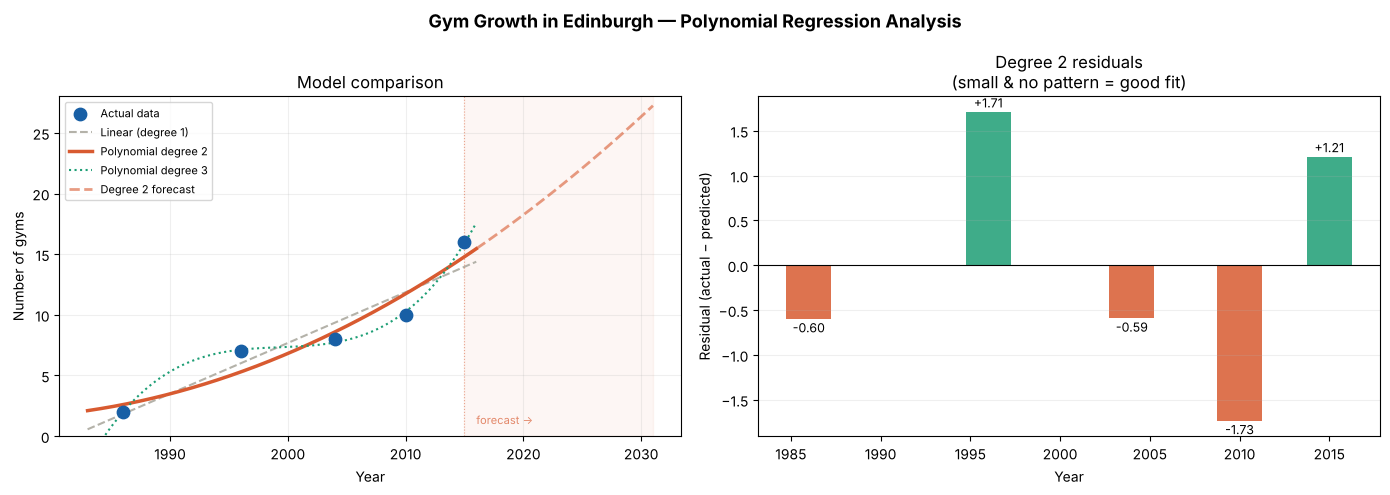

Chart saved as gym_regression.png


In [9]:
# Generate a smooth range of x values for drawing the curves
# np.linspace gives evenly spaced values between two numbers
x_fit_range      = np.linspace(1983, 2016, 300)         # within data range (solid line)
x_forecast_range = np.linspace(2015, 2031, 100)         # beyond data range (dashed line)

# Centre both ranges
x_fit_c      = x_fit_range      - x_center
x_forecast_c = x_forecast_range - x_center

# Create a figure with two subplots side by side
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Gym Growth in Edinburgh — Polynomial Regression Analysis", fontsize=13, fontweight='bold')

# ── Left chart: model fits and forecast ──────────────────────────────────────

# Actual data points
ax1.scatter(x, y, color='#185FA5', zorder=5, s=80, label='Actual data')

# Degree 1 (linear) — dashed grey baseline
ax1.plot(x_fit_range, model_d1(x_fit_c),
         color='#B4B2A9', linewidth=1.5, linestyle='--', label='Linear (degree 1)')

# Degree 2 — solid orange, our main model
ax1.plot(x_fit_range, model_d2(x_fit_c),
         color='#D85A30', linewidth=2.5, label='Polynomial degree 2')

# Degree 3 — dashed green for comparison
ax1.plot(x_fit_range, model_d3(x_fit_c),
         color='#1D9E75', linewidth=1.5, linestyle=':', label='Polynomial degree 3')

# Forecast extension — dashed orange beyond 2015
ax1.plot(x_forecast_range, model_d2(x_forecast_c),
         color='#D85A30', linewidth=2, linestyle='--', alpha=0.6, label='Degree 2 forecast')

# Shade the forecast region so it's clearly extrapolation
ax1.axvspan(2015, 2031, alpha=0.05, color='#D85A30', label='_nolegend_')
ax1.axvline(x=2015, color='#D85A30', linewidth=0.8, linestyle=':', alpha=0.5)
ax1.text(2016, 1, 'forecast →', fontsize=8, color='#D85A30', alpha=0.7)

ax1.set_xlabel('Year')
ax1.set_ylabel('Number of gyms')
ax1.set_title('Model comparison')
ax1.legend(fontsize=8)
ax1.set_ylim(0, 28)
ax1.grid(True, alpha=0.2)

# ── Right chart: residuals for degree 2 ─────────────────────────────────────

# Colour bars green if positive, red if negative
bar_colors = ['#1D9E75' if r >= 0 else '#D85A30' for r in residuals]

ax2.bar(years, residuals, color=bar_colors, width=2.5, alpha=0.85)
ax2.axhline(y=0, color='black', linewidth=0.8)  # zero line

# Label each bar with its value
for yr, res in zip(years, residuals):
    ax2.text(yr, res + (0.05 if res >= 0 else -0.15),
             f'{res:+.2f}', ha='center', fontsize=9)

ax2.set_xlabel('Year')
ax2.set_ylabel('Residual (actual − predicted)')
ax2.set_title('Degree 2 residuals\n(small & no pattern = good fit)')
ax2.grid(True, alpha=0.2, axis='y')

plt.tight_layout()
plt.savefig('gym_regression.png', dpi=150, bbox_inches='tight')
plt.show()
print("Chart saved as gym_regression.png")

## Cell 10 — Summary and conclusions

This cell brings everything together into a printed summary — useful for presenting your findings.

In [10]:
r2_d1 = evaluate_model(model_d1, x_c, y, 1)['R²']
r2_d2 = evaluate_model(model_d2, x_c, y, 2)['R²']

print("=" * 50)
print("SUMMARY")
print("=" * 50)
print(f"\nData points:          {len(years)} observations (1986–2015)")
print(f"\nModel comparison:")
print(f"  Linear R²:          {r2_d1}")
print(f"  Polynomial R²:      {r2_d2}  ← chosen model")
print(f"\nDegree 2 equation:")
print(f"  y = {coeffs_d2[0]:.4f}·t² + {coeffs_d2[1]:.4f}·t + {coeffs_d2[2]:.4f}")
print(f"  where t = year − {x_center}")
print(f"\nForecasts (degree 2 polynomial):")
for yr, val in zip(forecast_years, forecast_values):
    print(f"  {yr}: {val:.1f} gyms projected")
print(f"\nLimitation: only {len(years)} data points — treat forecasts as")
print(f"directional projections, not precise predictions.")
print("=" * 50)

SUMMARY

Data points:          5 observations (1986–2015)

Model comparison:
  Linear R²:          0.8982
  Polynomial R²:      0.9215  ← chosen model

Degree 2 equation:
  y = 0.0080·t² + 0.4125·t + 6.8131
  where t = year − 2000

Forecasts (degree 2 polynomial):
  2018: 16.8 gyms projected
  2020: 18.2 gyms projected
  2022: 19.7 gyms projected
  2025: 22.1 gyms projected
  2030: 26.3 gyms projected

Limitation: only 5 data points — treat forecasts as
directional projections, not precise predictions.
